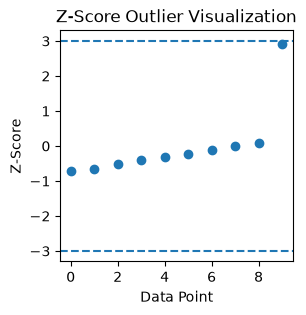

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)),z_scores)


plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x227048f8920>,
 'caps': [<matplotlib.lines.Line2D at 0x22704915910>,
 'boxes': [<matplotlib.lines.Line2D at 0x227049011c0>],
 'medians': [<matplotlib.lines.Line2D at 0x22704915d00>],
 'fliers': [<matplotlib.lines.Line2D at 0x22704915fa0>],
 'means': []}

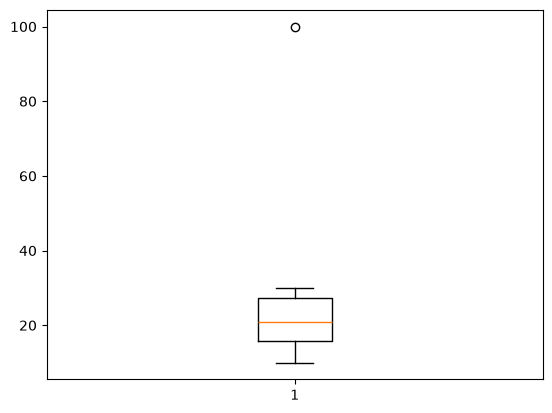

In [9]:
plt.boxplot(data)

In [10]:
import seaborn as sns
import pandas as pd 

df=sns.load_dataset('tips')

In [11]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


{'whiskers': [<matplotlib.lines.Line2D at 0x22704b64bc0>,
 'caps': [<matplotlib.lines.Line2D at 0x22704b64f80>,
 'boxes': [<matplotlib.lines.Line2D at 0x22704952750>],
 'medians': [<matplotlib.lines.Line2D at 0x22704b65460>],
 'fliers': [<matplotlib.lines.Line2D at 0x22704b65700>],
 'means': []}

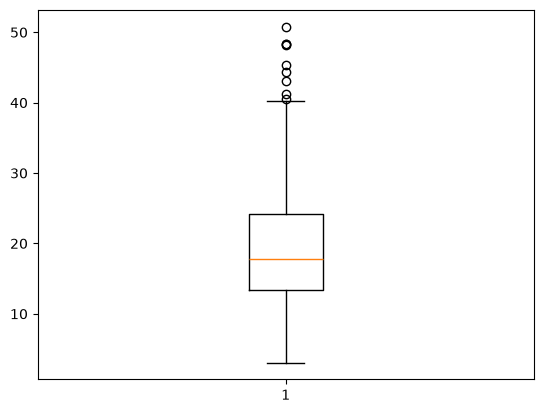

In [12]:
plt.boxplot(df['total_bill'])

In [13]:
q1=df['total_bill'].quantile(0.25)
q3=df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower=q1-1.5*iqr

upper= q3-1.5*iqr

df=df[(df['total_bill']<upper) & (df['total_bill']>lower)]

iqr----- 10.779999999999998


In [14]:
df.shape

(7, 7)

In [15]:
q1=df['tip'].quantile(0.25)
q3=df['tip'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower=q1-1.5*iqr
print('lower--------', lower)
upper= q3-1.5*iqr
print('upper--------', upper)

iqr----- 0.72
lower-------- -0.08000000000000007
upper-------- 0.6399999999999999


{'whiskers': [<matplotlib.lines.Line2D at 0x22704b9be00>,
 'caps': [<matplotlib.lines.Line2D at 0x22704bd0380>,
 'boxes': [<matplotlib.lines.Line2D at 0x22704b9bb90>],
 'medians': [<matplotlib.lines.Line2D at 0x22704bd08c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x22704b9a4e0>],
 'means': []}

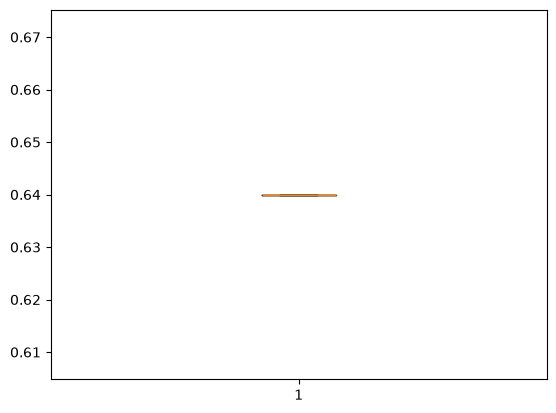

In [16]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [17]:
df

,total_bill,tip,sex,smoker,day,time,size
67,3.07,0.64,Female,Yes,Sat,Dinner,1
92,5.75,0.64,Female,Yes,Fri,Dinner,2
111,7.25,0.64,Female,No,Sat,Dinner,1
149,7.51,0.64,Male,No,Thur,Lunch,2
172,7.25,0.64,Male,Yes,Sun,Dinner,2
195,7.56,0.64,Male,No,Thur,Lunch,2
218,7.74,0.64,Male,Yes,Sat,Dinner,2


In [18]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

In [19]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [20]:
num_fea=['total_bill']
ohe_fea=['sex','smoker']
min_max=['tip']

In [21]:
from sklearn.preprocessing import MinMaxScaler

transform=ColumnTransformer(

transformers=[('num',StandardScaler(),num_fea),
('min_max',MinMaxScaler(),min_max),
('cat',OneHotEncoder(drop='first'),ohe_fea),
], remainder='passthrough'
)

In [22]:
transform.fit_transform(df)

array([[-2.253647015330439, 0.0, 0.0, 1.0, 'Sat', 'Dinner', 1],
       [-0.5378021286584006, 0.0, 0.0, 1.0, 'Fri', 'Dinner', 2],
       [0.4225588153744568, 0.0, 0.0, 0.0, 'Sat', 'Dinner', 1],
       [0.5890213790068185, 0.0, 1.0, 0.0, 'Thur', 'Lunch', 2],
       [0.4225588153744568, 0.0, 1.0, 1.0, 'Sun', 'Dinner', 2],
       [0.6210334104745804, 0.0, 1.0, 0.0, 'Thur', 'Lunch', 2],
       [0.7362767237585236, 0.0, 1.0, 1.0, 'Sat', 'Dinner', 2]],
      dtype=object)

In [23]:
pd.DataFrame(transform.fit_transform(df),columns=transform.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-2.253647,0.0,0.0,1.0,Sat,Dinner,1
1,-0.537802,0.0,0.0,1.0,Fri,Dinner,2
2,0.422559,0.0,0.0,0.0,Sat,Dinner,1
3,0.589021,0.0,1.0,0.0,Thur,Lunch,2
4,0.422559,0.0,1.0,1.0,Sun,Dinner,2
5,0.621033,0.0,1.0,0.0,Thur,Lunch,2
6,0.736277,0.0,1.0,1.0,Sat,Dinner,2


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

Pipeline([
    ('preprocessor', transform),
    ('classifier', LogisticRegression())
])



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('min_max', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: flo